In [1]:
from sparse_state_preparation import (
    find_bijection_and_circuit,
    fast_toffoli_counter,
    SparseStatePreparation,
    random_tableau,
    random_signs,
)

from qualtran.drawing import (
    show_bloq,
    ClassicalSimGraphDrawer,
    get_musical_score_data,
    draw_musical_score,
)
from qualtran.bloqs.rotations import PhaseGradientState
from qualtran.resource_counting import get_cost_value, QubitCount, QECGatesCost
from qualtran import QFxp, QUInt, BloqBuilder


import numpy as np

## Sparse state preparation

In this notebook we show how to create efficient circuits for preparing sparse quantum states.
For this we extensively use the Qualtran framework.

The first state to prepare is a sparse quantum state on 12 qubits with 13 non-zero basis states.

In [18]:
coeffs = np.array(
    [
        0.02971151 + 0.0j,
        -0.06864128 + 0.02082211j,
        -0.03502327 + 0.11545623j,
        0.17448621 + 0.14319713j,
        -0.06298578 - 0.06298578j,
        0.248791 - 0.37234205j,
        -0.10245455 + 0.33774739j,
        0.28825977 - 0.02839111j,
        -0.12789431 - 0.42161103j,
        -0.25306989 - 0.47346045j,
        0.05932731 + 0.04868866j,
        0.08121976 - 0.08121976j,
        0.08871471 + 0.047419j,
    ]
)

states = np.array(
    [
        [True, True, False, False, True, True, False, False, False, True, False, True],
        [False, True, True, False, True, True, True, False, False, True, True, False],
        [True, False, False, True, False, True, False, False, False, True, True, False],
        [False, True, True, False, True, False, True, False, False, True, True, False],
        [False, False, True, True, True, True, False, False, False, True, True, False],
        [False, False, False, True, True, True, False, False, False, True, True, False],
        [False, True, False, False, False, True, False, False, True, True, True, False],
        [False, True, True, True, True, False, False, False, False, True, True, False],
        [True, False, False, False, True, True, False, False, False, True, True, False],
        [True, True, False, True, True, True, True, False, False, True, True, False],
        [False, True, True, True, True, True, False, False, False, True, True, False],
        [True, True, True, False, False, False, False, False, False, True, True, False],
        [True, True, True, False, True, True, False, False, False, True, True, False],
    ]
)

The preparation circuit is given as a Qualtran Bloq. It requirs a ``phase_gradient`` register which is not changed during the sparse state preparation.
The output is a 12-qubit ``state`` register.

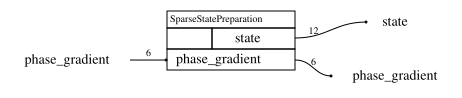

In [19]:
sparse_prep = SparseStatePreparation(states, coeffs, QFxp(6, 6))

show_bloq(sparse_prep)

Decomposing the plot shows that it consists of a Bloq ``DenseStatePreparationViaQROAM`` on $4=\lceil \log_2(13) \rceil$ qubits, followed by the adjoint of ``IsometryToSubspaceViaBatching``, i.e. an isometry from the ``subspace`` into the full ``state``.

The phase ``phase_gradient`` is required for the rotations in the dense preparation Bloq. 

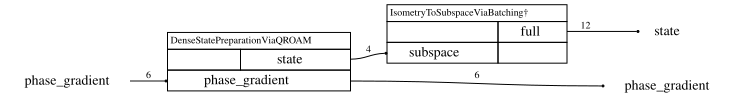

In [20]:
show_bloq(sparse_prep.decompose_bloq())

We can look at the two sub-Bloqs individually.

In the ``DenseStatePreparationViaQROAM``-Bloq one first prepares the amplitudes, followed by the phases.
Finally sign-flips caused by X-measurements for freeing target qubits of QRO(A)MS are fixed in the ``SignFixUp``-Bloq.

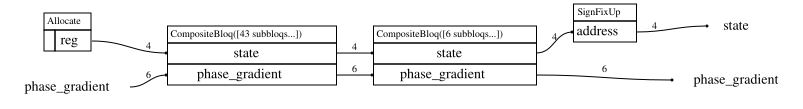

In [21]:
show_bloq(sparse_prep.dense_state_prep.decompose_bloq())

The ``IsometryToSubspaceViaBatching``-Bloq, mapping from the full state register to the subspace register, consists of pairs of ``BatchCreation`` and ``BatchZeroing`` Bloqs.
After a batch is zeroed, all elements within it lie in the subspace and are invariant under all further operations.

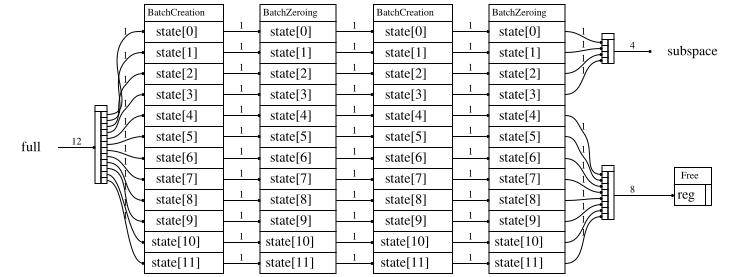

In [22]:
show_bloq(sparse_prep.isometry.decompose_bloq())

Zooming in reveals the gates applied for creating and zeroing a batch. 
The zeroing operation consists of a ``PartialUnaryIteration``-Bloq.

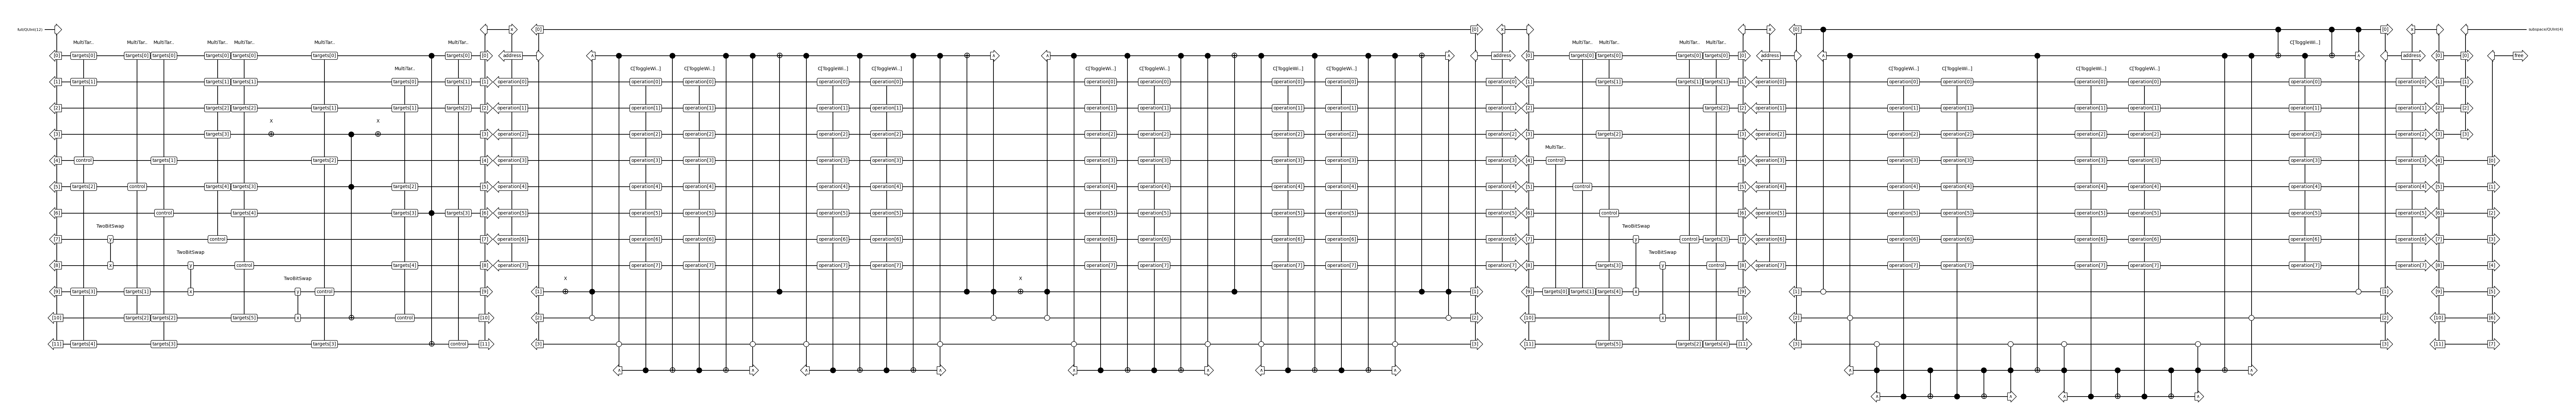

In [23]:
msd = get_musical_score_data(
    sparse_prep.isometry.decompose_bloq().flatten_once().flatten_once()
)
fig, ax = draw_musical_score(msd, max_width=1000, max_height=1000)

The mapping for a single state looks as follows.

full state: [False  True  True  True  True  True False False False  True  True False]


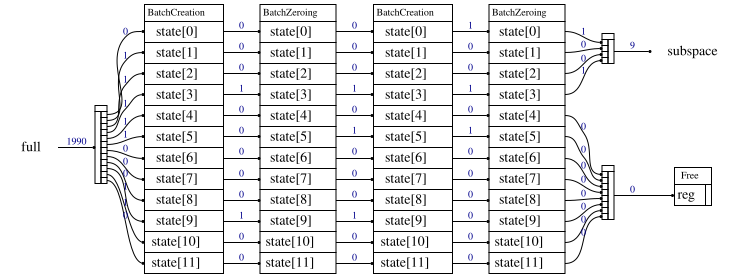

In [24]:
print("full state:", states[10])
s = QUInt(sparse_prep.isometry.state_bitsize).from_bits_array(states)[10]
drawer = ClassicalSimGraphDrawer(
    sparse_prep.isometry.decompose_bloq(), vals={"full": s}
)
drawer.get_svg()

We can check that the correct sparse state is prepared using a tensor simulation.
For this a ``PhaseGradientState`` needs to be created and freed after use.
The number of bits of the phase gradient register determines the accuracy of the rotations in the dense state preparation sub-Bloq. 

In order to allow for a (non-superoperator) tensor simulation we need to replace some incompatible parts of the circuit.
In this ``tensor_simulation`` mode one should not do ressource estimates.
The classical logic for keeping track of the X-measurement results for later uncomputing is not implemented yet. It is assumed that regardless of the state, always |+> is measured.

In [25]:
for state, coeff in zip(states, coeffs):
    print(state, coeff)

phase_bitsize = 8
sparse_prep_tensor = SparseStatePreparation(
    states, coeffs, QFxp(phase_bitsize, phase_bitsize), tensor_simulation=True
)

bb = BloqBuilder()
phase_gradient = bb.add(PhaseGradientState(phase_bitsize))
state, phase_gradient = bb.add(sparse_prep_tensor, phase_gradient=phase_gradient)
bb.add(PhaseGradientState(bitsize=phase_bitsize).adjoint(), phase_grad=phase_gradient)
bloq = bb.finalize(state=state)
prepared_state = bloq.tensor_contract()

for i, x in enumerate(prepared_state):
    if not np.isclose(x, 0):
        print(bin(i), x)

[ True  True False False  True  True False False False  True False  True] (0.02971151+0j)
[False  True  True False  True  True  True False False  True  True False] (-0.06864128+0.02082211j)
[ True False False  True False  True False False False  True  True False] (-0.03502327+0.11545623j)
[False  True  True False  True False  True False False  True  True False] (0.17448621+0.14319713j)
[False False  True  True  True  True False False False  True  True False] (-0.06298578-0.06298578j)
[False False False  True  True  True False False False  True  True False] (0.248791-0.37234205j)
[False  True False False False  True False False  True  True  True False] (-0.10245455+0.33774739j)
[False  True  True  True  True False False False False  True  True False] (0.28825977-0.02839111j)
[ True False False False  True  True False False False  True  True False] (-0.12789431-0.42161103j)
[ True  True False  True  True  True  True False False  True  True False] (-0.25306989-0.47346045j)
[False  True  T

With Qualtran it is easy to compute the ressources needed for the Bloqs. 
We do this on a larger example to not get caught up by constant terms of the cost.

In [26]:
num_qubits = 30
num_states = 10**3

seed = 8769876986

rng = np.random.default_rng(seed)
states = random_tableau(num_states, num_qubits, seed=seed)

real_ = rng.normal(loc=0.0, scale=1.0, size=num_states)
imag_ = rng.normal(loc=0.0, scale=1.0, size=num_states)
complex_ = imag_ + 1.0j * imag_

coeffs = complex_ / np.linalg.norm(complex_)

toffoli_cost = lambda cost: cost.and_bloq + cost.cswap


def print_costs(prep: SparseStatePreparation):
    full_q, full_toff = (
        get_cost_value(prep, QubitCount()),
        toffoli_cost(get_cost_value(prep, QECGatesCost())),
    )
    dense_q, dense_toff = (
        get_cost_value(prep.dense_state_prep, QubitCount()),
        toffoli_cost(get_cost_value(prep.dense_state_prep, QECGatesCost())),
    )
    iso_q, iso_toff = (
        get_cost_value(prep.dense_state_prep, QubitCount()),
        toffoli_cost(get_cost_value(prep.isometry, QECGatesCost())),
    )

    fmt = lambda row: " ".join(f"{str(item).ljust(12)}" for item in row)
    print(fmt(["", "qubits", "toffolis"]))
    print(fmt(["dense prep", dense_q, dense_toff]))
    print(fmt(["isometry", iso_q, iso_toff]))
    print(fmt(["full", full_q, full_toff]), "\n")

In [11]:
sparse_prep = SparseStatePreparation(states, coeffs, QFxp(15, 15))

print_costs(sparse_prep)

             qubits       toffolis    
dense prep   152          890         
isometry     152          1060        
full         152          1950         



It is possible to trade-off qubits for Toffoli gates in the dense state preparation by setting the maximum ``k`` used in the QRO(A)Ms.
If no ``max_k`` is given the one with the (approximate) best Toffoli count is used.

In [12]:
for max_k in range(4):
    print("max_k:", max_k)
    sparse_prep = SparseStatePreparation(states, coeffs, QFxp(15, 15), max_k=max_k)
    print_costs(sparse_prep)

max_k: 0
             qubits       toffolis    
dense prep   55           2295        
isometry     55           1060        
full         55           3355         

max_k: 1
             qubits       toffolis    
dense prep   64           1658        
isometry     64           1060        
full         64           2718         

max_k: 2
             qubits       toffolis    
dense prep   93           1143        
isometry     93           1060        
full         93           2203         

max_k: 3
             qubits       toffolis    
dense prep   152          961         
isometry     152          1060        
full         152          2021         



One part of the cost in the dense state preparation is due to the ``SignFixUp``-Bloq fixing the signs of the basis states.
This can instead be done in the isometry. 
The isometry circuit and also the cost change, with the main difference being, that the unrestricted ``PartialUnaryIteratioin`` from before is replaced by the restricted version.

In [13]:
for max_k in range(4):
    print("max_k:", max_k)
    sparse_prep = SparseStatePreparation(
        states, coeffs, QFxp(15, 15), max_k=max_k, uncompute_in_isometry=True
    )
    print_costs(sparse_prep)

max_k: 0
             qubits       toffolis    
dense prep   55           1883        
isometry     55           1251        
full         56           3134         

max_k: 1
             qubits       toffolis    
dense prep   64           1221        
isometry     64           1251        
full         64           2472         

max_k: 2
             qubits       toffolis    
dense prep   93           897         
isometry     93           1251        
full         93           2148         

max_k: 3
             qubits       toffolis    
dense prep   152          829         
isometry     152          1251        
full         152          2080         



### Real states

For states that only have real coefficients not only the sign-flip-corrections, but also the phase encoding (which are $\pm 1$) can be done in the isometry.

In [14]:
for max_k in range(4):
    print("max_k:", max_k)
    sparse_prep = SparseStatePreparation(
        states,
        np.abs(coeffs),
        QFxp(15, 15),
        max_k=max_k,
        uncompute_in_isometry=True,
        add_real_phase_in_isometry=True,
    )
    print_costs(sparse_prep)

max_k: 0
             qubits       toffolis    
dense prep   54           1129        
isometry     54           1251        
full         56           2380         

max_k: 1
             qubits       toffolis    
dense prep   62           718         
isometry     62           1251        
full         62           1969         

max_k: 2
             qubits       toffolis    
dense prep   91           588         
isometry     91           1251        
full         91           1839         

max_k: 3
             qubits       toffolis    
dense prep   150          585         
isometry     150          1251        
full         150          1836         



In this case the ``DenseStatePreparationViaQROAM``-Bloq is just the Bloq for encoding the amplitudes.

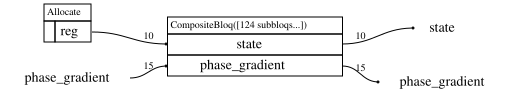

In [15]:
sparse_prep = SparseStatePreparation(
    states,
    np.abs(coeffs),
    QFxp(15, 15),
    uncompute_in_isometry=True,
    add_real_phase_in_isometry=True,
)

show_bloq(sparse_prep.dense_state_prep.decompose_bloq())

### Interface to Rust code

When building ``IsometryToSubspaceViaBatching`` the Bloq uses the function ``find_bijection_and_circuit``.
This is a Python-binding for Rust code that implements the classical algorithms for finding the isometry circuit.

If one wants to get the Toffoli cost for the isometry in larger problem instances, getting ressource counts via Qualtran can be inefficient. 
In these cases the function ``fast_toffoli_counter`` may be used to get upper bounds on the Toffoli cost.
The bound should be almost tight in most cases.

In [16]:
states = random_tableau(10**5, 100, seed=seed)

_, circ = find_bijection_and_circuit(states, None, None)
fast_toffoli_counter(circ)

104924

The restricted version of the isometry algorithm is used if a list of signs is provided.

In [17]:
signs = random_signs(10**5, seed=seed)

_, circ = find_bijection_and_circuit(states, signs, None)
fast_toffoli_counter(circ)

114061